# GEP for 0–1 knapsack: ISCMI 2026 confirmatory experiment

This notebook is the readable, cell-by-cell view of protocol V2. It does **not**
launch the multi-hour evolutionary experiment. It loads the frozen artifacts,
shows the data, exposes the important source functions, and rebuilds the advisor
tables and figures.

The knapsack problem chooses binary item decisions $x_i\in\{0,1\}$:

$$
\max \sum_i p_i x_i \qquad \text{subject to}\qquad
\sum_i w_i x_i\le c.
$$

For certified optimum $O_i$ and recovered profit $H_i$, the main error is

$$
g_i=10^6\frac{O_i-H_i}{O_i}.
$$

Lower gap is better, and $g_i=0$ means exact recovery.

## Module 1 — Use the project kernel and locate the experiment

Choose **Python (.venv — ISCMI 2026 V2)** in Jupyter. The first cell prints the
exact interpreter and package versions so a wrong kernel is obvious immediately.

In [1]:
from pathlib import Path
import os, sys, json, inspect

start = Path.cwd().resolve()
candidates = [start, *start.parents]
ROOT = next(path for path in candidates if (path / "src" / "config.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scipy
import sympy as sp
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

print("Experiment root:", ROOT)
print("Python kernel:", sys.executable)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "pandas:", pd.__version__, "SciPy:", scipy.__version__)
print("SymPy:", sp.__version__)
assert ".venv" in Path(sys.executable).as_posix(), "Select the project .venv kernel"

Experiment root: /private/tmp/gep-kp-iscmi-2026-stage
Python kernel: /Users/hugomrdz/Documents/Projects/gep-kp/.venv/bin/python
Python: 3.14.7
NumPy: 2.5.2 pandas: 3.0.5 SciPy: 1.18.1
SymPy: 1.14.0


## Module 2 — What is in the Jooken dataset?

The archive contains 3,240 generated 0–1 knapsack cases. Each name records:

- $n$: number of items;
- $c$: generator coefficient scale;
- $g$: correlation/generator setting;
- $f$: capacity fraction;
- $\epsilon$: perturbation level;
- $s$: perturbation bound (not a random seed).

There are 2,977 cases with supplied certified optima and 263 unresolved cases.
The in-distribution pool keeps the three $s$ siblings together, then makes a
reproducible group-random train/validation/ID split. The larger item-count and
coefficient levels form three explicit OOD regions.

In [2]:
from src.config import RESULTS_ROOT, SPLIT_MANIFEST, ARM_ORDER, TERMINAL_SETS
from src.dataset import validate_split_manifest

split = pd.read_csv(SPLIT_MANIFEST)
validate_split_manifest(split)
partition_table = (
    split.groupby(["partition", "region"], dropna=False)
    .agg(instances=("name", "size"), groups=("group_id", "nunique"), certified=("certified", "sum"))
    .reset_index()
)
display(partition_table)
assert len(split) == 3240
assert int(split["certified"].sum()) == 2977

,partition,region,instances,groups,certified
0,id_test,ID,345,115,345
1,ood_c,OOD-c,667,235,667
2,ood_n,OOD-n,432,144,432
3,ood_nc,OOD-nc,150,53,150
4,train,ID,1038,346,1038
5,unresolved,OOD-c,197,76,0
6,unresolved,OOD-nc,66,24,0
7,validation,ID,345,115,345


## Module 3 — Look at actual knapsack items

Each point below is one item. The dashed line is not a feasibility boundary; it
simply helps show how profit and weight scales differ across example cases.
Color marks what the transparent MAXPW density rule packs.

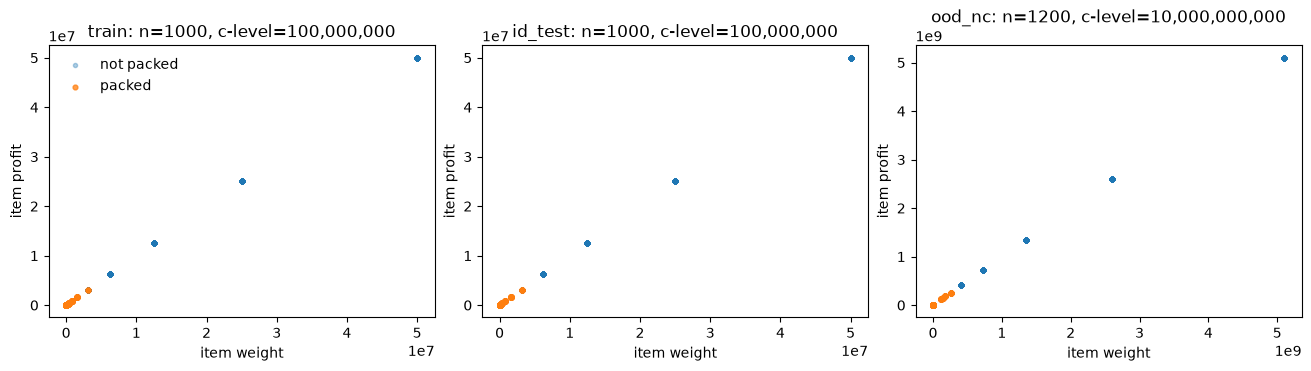

In [3]:
from src.config import JOOKEN_ARCHIVE
from src.dataset import load_partitions
from src.baselines import baseline_scores
from src.gep import pack_by_scores

examples = []
for partition in ("train", "id_test", "ood_nc"):
    examples.append(load_partitions(SPLIT_MANIFEST, [partition], JOOKEN_ARCHIVE)[0])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, instance in zip(axes, examples):
    solution = pack_by_scores(instance, baseline_scores(instance)["MAXPW"], "MAXPW")
    ax.scatter(instance.weights[~solution.selected], instance.profits[~solution.selected], s=9, alpha=.35, label="not packed")
    ax.scatter(instance.weights[solution.selected], instance.profits[solution.selected], s=12, alpha=.75, label="packed")
    ax.set_title(f"{instance.partition}: n={instance.n}, c-level={instance.c:,}")
    ax.set_xlabel("item weight")
    ax.set_ylabel("item profit")
axes[0].legend(frameon=False)
plt.show()

## Module 4 — The four terminal configurations

All arms share normalized profit $P$, normalized weight $W$, original row signal
$O$, and constants 1 and 0. `CAP` adds per-item capacity use $K=w_i/c$ and
instance tightness $T=c/\sum_jw_j$. `SCALE` adds log-normalized profit $L$.
`FULL` contains both feature groups. This is a $2\times2$ information ablation,
not four arbitrary formulas.

In [4]:
terminal_table = pd.DataFrame(
    [{"arm": arm, "terminals": " ".join(terminals)} for arm, terminals in TERMINAL_SETS.items()]
)
display(terminal_table)

from src import gep
display(Markdown("### Terminal construction used by every evaluation"))
display(Code(inspect.getsource(gep.terminal_environment), language="python"))

,arm,terminals
0,BASE,P W O 1 0
1,CAP,P W O K T 1 0
2,SCALE,P W O L 1 0
3,FULL,P W O K T L 1 0


### Terminal construction used by every evaluation

def terminal_environment(instance: KnapsackInstance, arm: str) -> dict[str, np.ndarray]:
    profits = instance.profits.astype(np.float64)
    weights = instance.weights.astype(np.float64)
    n = instance.n
    shared = {
        "P": profits / profits.max(),
        "W": weights / weights.max(),
        "O": 1.0 - np.arange(n, dtype=np.float64) / max(n - 1, 1),
        "1": np.ones(n, dtype=np.float64),
        "0": np.zeros(n, dtype=np.float64),
    }
    if "K" in TERMINAL_SETS[arm]:
        shared["K"] = weights / instance.capacity
    if "T" in TERMINAL_SETS[arm]:
        shared["T"] = np.full(
            n, instance.capacity / instance.weights.sum(dtype=np.int64), dtype=np.float64
        )
    if "L" in TERMINAL_SETS[arm]:
        shared["L"] = np.log1p(profits) / np.log1p(profits.max())
    if set(shared) != set(TERMINAL_SETS[arm]):
        raise AssertionError(f"Terminal environment mismatch for {arm}: {set(shared)}")
    return shared

## Module 5 — How a gene becomes a feasible solution

A valid GEP gene decodes into one arithmetic priority expression. Its score is
computed for every item, scores are sanitized, and a stable descending sort is
scanned once. An item is accepted only when it still fits. The oracle optimum is
used for training and grading, never as a terminal.

Protected division returns 1 when $|b|\le10^{-12}$.

In [5]:
for function in (gep.decode_gene, gep.evaluate_tree, gep.pack_by_scores):
    display(Markdown(f"### `{function.__name__}`"))
    display(Code(inspect.getsource(function), language="python"))

### `decode_gene`

def decode_gene(gene: str, arm: str) -> tuple[Node, int]:
    if arm not in TERMINAL_SETS:
        raise ValueError(f"Unknown terminal arm {arm!r}")
    if not gene:
        raise ValueError("Gene cannot be empty")
    root = Node(gene[0], arm)
    awaiting: deque[Node] = deque([root] if root.arity else [])
    cursor = 1
    while awaiting:
        parent = awaiting.popleft()
        for _ in range(parent.arity):
            if cursor >= len(gene):
                raise ValueError("Gene ended before its expression tree closed")
            child = Node(gene[cursor], arm)
            cursor += 1
            parent.children.append(child)
            if child.arity:
                awaiting.append(child)
    return root, cursor

### `evaluate_tree`

def evaluate_tree(node: Node, environment: dict[str, np.ndarray]) -> np.ndarray:
    if node.arity == 0:
        return environment[node.symbol]
    arguments = [evaluate_tree(child, environment) for child in node.children]
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        result = PRIMITIVES[node.symbol].function(*arguments)
    return np.asarray(result, dtype=np.float64)

### `pack_by_scores`

def pack_by_scores(
    instance: KnapsackInstance, scores: np.ndarray, method: str
) -> PackingSolution:
    values = sanitize_scores(scores, (instance.n,))
    item_ids = np.arange(instance.n, dtype=np.int64)
    order = np.lexsort((item_ids, -values))
    selected = np.zeros(instance.n, dtype=bool)
    remaining = instance.capacity
    for item_value in order:
        item = int(item_value)
        weight = int(instance.weights[item])
        if weight <= remaining:
            selected[item] = True
            remaining -= weight
    total_weight = int(instance.weights[selected].sum(dtype=np.int64))
    total_profit = int(instance.profits[selected].sum(dtype=np.int64))
    if total_weight > instance.capacity:
        raise AssertionError(f"{method} generated an infeasible solution")
    return PackingSolution(selected, total_weight, total_profit, method)

## Module 6 — Evolution and the fair budget

Evolution lexicographically minimizes mean training gap and then ORF length:

$$
\left(\frac{1}{|S|}\sum_{i\in S}g_i,\;|\operatorname{ORF}|\right).
$$

All four arms use one configuration selected by `irace` on train/validation
only. Each final run receives 65,536 raw chromosome requests, and duplicate
phenotypes still consume a raw request. The final experiment has 75 paired
master seeds per arm.

In [6]:
from src.runs import SELECTED_CONFIG_PATH, MODELS_PATH, CHECKPOINTS_PATH

selected = json.loads(Path(SELECTED_CONFIG_PATH).read_text())
display(pd.DataFrame([selected["parameters"]]))
display(Markdown("### Exact evolutionary loop"))
display(Code(inspect.getsource(gep.evolve_priority_formula), language="python"))

,budget,crossover_rate,elite_fraction,expected_mutations,head_length,population_size,tournament_size
0,65536,0.7,0.01,3,10,512,7


### Exact evolutionary loop

def evolve_priority_formula(
    gap_function: Callable[[str], np.ndarray],
    training_case_count: int,
    arm: str,
    seed: int,
    config: SearchConfig,
    checkpoints: Iterable[int] = CHECKPOINTS,
) -> SearchOutcome:
    """Run GEP without early stopping and snapshot exact raw-request counts."""

    seed_sequence = np.random.SeedSequence(int(seed))
    initialization_seed, selection_seed, crossover_seed, mutation_seed = seed_sequence.spawn(4)
    initialization_rng = np.random.default_rng(initialization_seed)
    selection_rng = np.random.default_rng(selection_seed)
    crossover_rng = np.random.default_rng(crossover_seed)
    mutation_rng = np.random.default_rng(mutation_seed)
    population = [
        random_gene(initialization_rng, arm, config.head_length)
        for _ in range(config.population_size)
    ]
    cache: dict[str, float] = {}
    candidate_instance_evaluations = 0
    raw_requests = 0
    checkpoint_targets = set(int(value) for value in checkpoints if value <= config.budget)
    checkpoint_rows: list[dict[str, int | float | str]] = []
    generation_rows: list[dict[str, int | float | str]] = []
    global_best_gene = ""
    global_best_fitness: tuple[float, int, str, str] | None = None

    def evaluate(gene: str) -> tuple[float, int, str, str]:
        nonlocal candidate_instance_evaluations
        key = phenotype_key(gene, arm)
        if key not in cache:
            gaps = np.asarray(gap_function(gene), dtype=np.float64)
            if not np.isfinite(gaps).all() or np.any(gaps < -1e-7):
                raise AssertionError("Training produced invalid optimality gaps")
            cache[key] = float(gaps.mean())
            candidate_instance_evaluations += training_case_count
        return _fitness_tuple(cache[key], gene, arm)

    for population_index in range(config.populations):
        fitnesses: list[tuple[float, int, str, str]] = []
        for gene in population:
            fitness = evaluate(gene)
            fitnesses.append(fitness)
            raw_requests += 1
            if global_best_fitness is None or fitness < global_best_fitness:
                global_best_fitness = fitness
                global_best_gene = gene
            if raw_requests in checkpoint_targets:
                checkpoint_rows.append(
                    _checkpoint_row(
                        raw_requests,
                        global_best_gene,
                        global_best_fitness[0],
                        arm,
                        len(cache),
                        candidate_instance_evaluations,
                    )
                )
        order = sorted(range(len(population)), key=lambda index: fitnesses[index])
        current = fitnesses[order[0]]
        generation_rows.append(
            {
                "population_index": population_index,
                "raw_requests": raw_requests,
                "generation_best_gap_ppm": current[0],
                "global_best_gap_ppm": global_best_fitness[0],
                "global_best_gene": global_best_gene,
                "unique_orfs": len(cache),
                "candidate_instance_evaluations": candidate_instance_evaluations,
            }
        )
        if population_index + 1 == config.populations:
            break
        elites = [population[index] for index in order[: config.elite_count]]

        def select_parent() -> str:
            contenders = selection_rng.integers(
                0, len(population), size=config.tournament_size
            )
            winner = min((int(value) for value in contenders), key=lambda index: fitnesses[index])
            return population[winner]

        next_population = list(elites)
        while len(next_population) < config.population_size:
            parent_a, parent_b = select_parent(), select_parent()
            if crossover_rng.random() < config.crossover_rate:
                children = _recombine(parent_a, parent_b, arm, config, crossover_rng)
            else:
  

## Module 7 — Frozen model audit

This checks that the expected 300 confirmatory GEP models, 300 matched random
search controls, and 75 accepted-notebook continuity models are present. It also
shows elapsed time and how many distinct expressed ORFs were actually scored.

In [7]:
models = pd.read_csv(MODELS_PATH, dtype={"master_seed": str})
display(models.groupby(["family", "arm"], dropna=False).agg(
    models=("model_id", "nunique"),
    mean_minutes=("elapsed_seconds", lambda x: x.mean()/60),
    median_unique_orfs=("unique_orfs", "median"),
    median_train_gap_ppm=("train_mean_gap_ppm", "median"),
).reset_index())
assert models.groupby("family").size().to_dict() == {"AHDAS_BASE": 75, "GEP": 300, "RANDOM": 300}

,family,arm,models,mean_minutes,median_unique_orfs,median_train_gap_ppm
0,AHDAS_BASE,BASE,75,2.187267,6107.0,6107.167577
1,GEP,BASE,75,7.576403,20344.0,4887.590699
2,GEP,CAP,75,7.291767,19177.0,4805.161667
3,GEP,FULL,75,7.851421,19599.0,4504.168600
4,GEP,SCALE,75,7.989859,20165.0,4696.926644
5,RANDOM,BASE,75,4.782508,18504.0,5496.765860
6,RANDOM,CAP,75,3.940638,13598.0,6035.543213
7,RANDOM,FULL,75,3.730150,11887.0,5982.537211
8,RANDOM,SCALE,75,4.553054,15721.0,5360.696645


## Module 8 — Advisor headline: eight bars with honest error lines

The four GEP intervals resample both the 75 paired seed blocks and the 115 ID
sibling groups. The deterministic baselines have no fake repeated runs, so their
intervals resample only the sibling groups. Bar height is mean residual gap in
ppm; lower is better.

,method,order,mean_gap_ppm,ci95_low_ppm,ci95_high_ppm,interval,instances,groups,stochastic_runs,budget
0,BASE,1,5213.798887,4130.953740,6389.173125,95% crossed seed/group bootstrap,345,115,75,65536
1,CAP,2,5451.997212,4274.644029,6723.140575,95% crossed seed/group bootstrap,345,115,75,65536
2,SCALE,3,5050.211553,3962.735368,6241.938991,95% crossed seed/group bootstrap,345,115,75,65536
3,FULL,4,4905.631668,3852.077994,6042.668069,95% crossed seed/group bootstrap,345,115,75,65536
4,DEF,5,11514.553726,8853.129740,14352.007733,95% sibling-group bootstrap,345,115,1,0
5,MAXP,6,11114.304351,8463.288505,13961.047613,95% sibling-group bootstrap,345,115,1,0
6,MAXPW,7,7695.286023,4691.319950,11130.885275,95% sibling-group bootstrap,345,115,1,0
7,MINW,8,18089.951947,13340.476281,23255.606949,95% sibling-group bootstrap,345,115,1,0


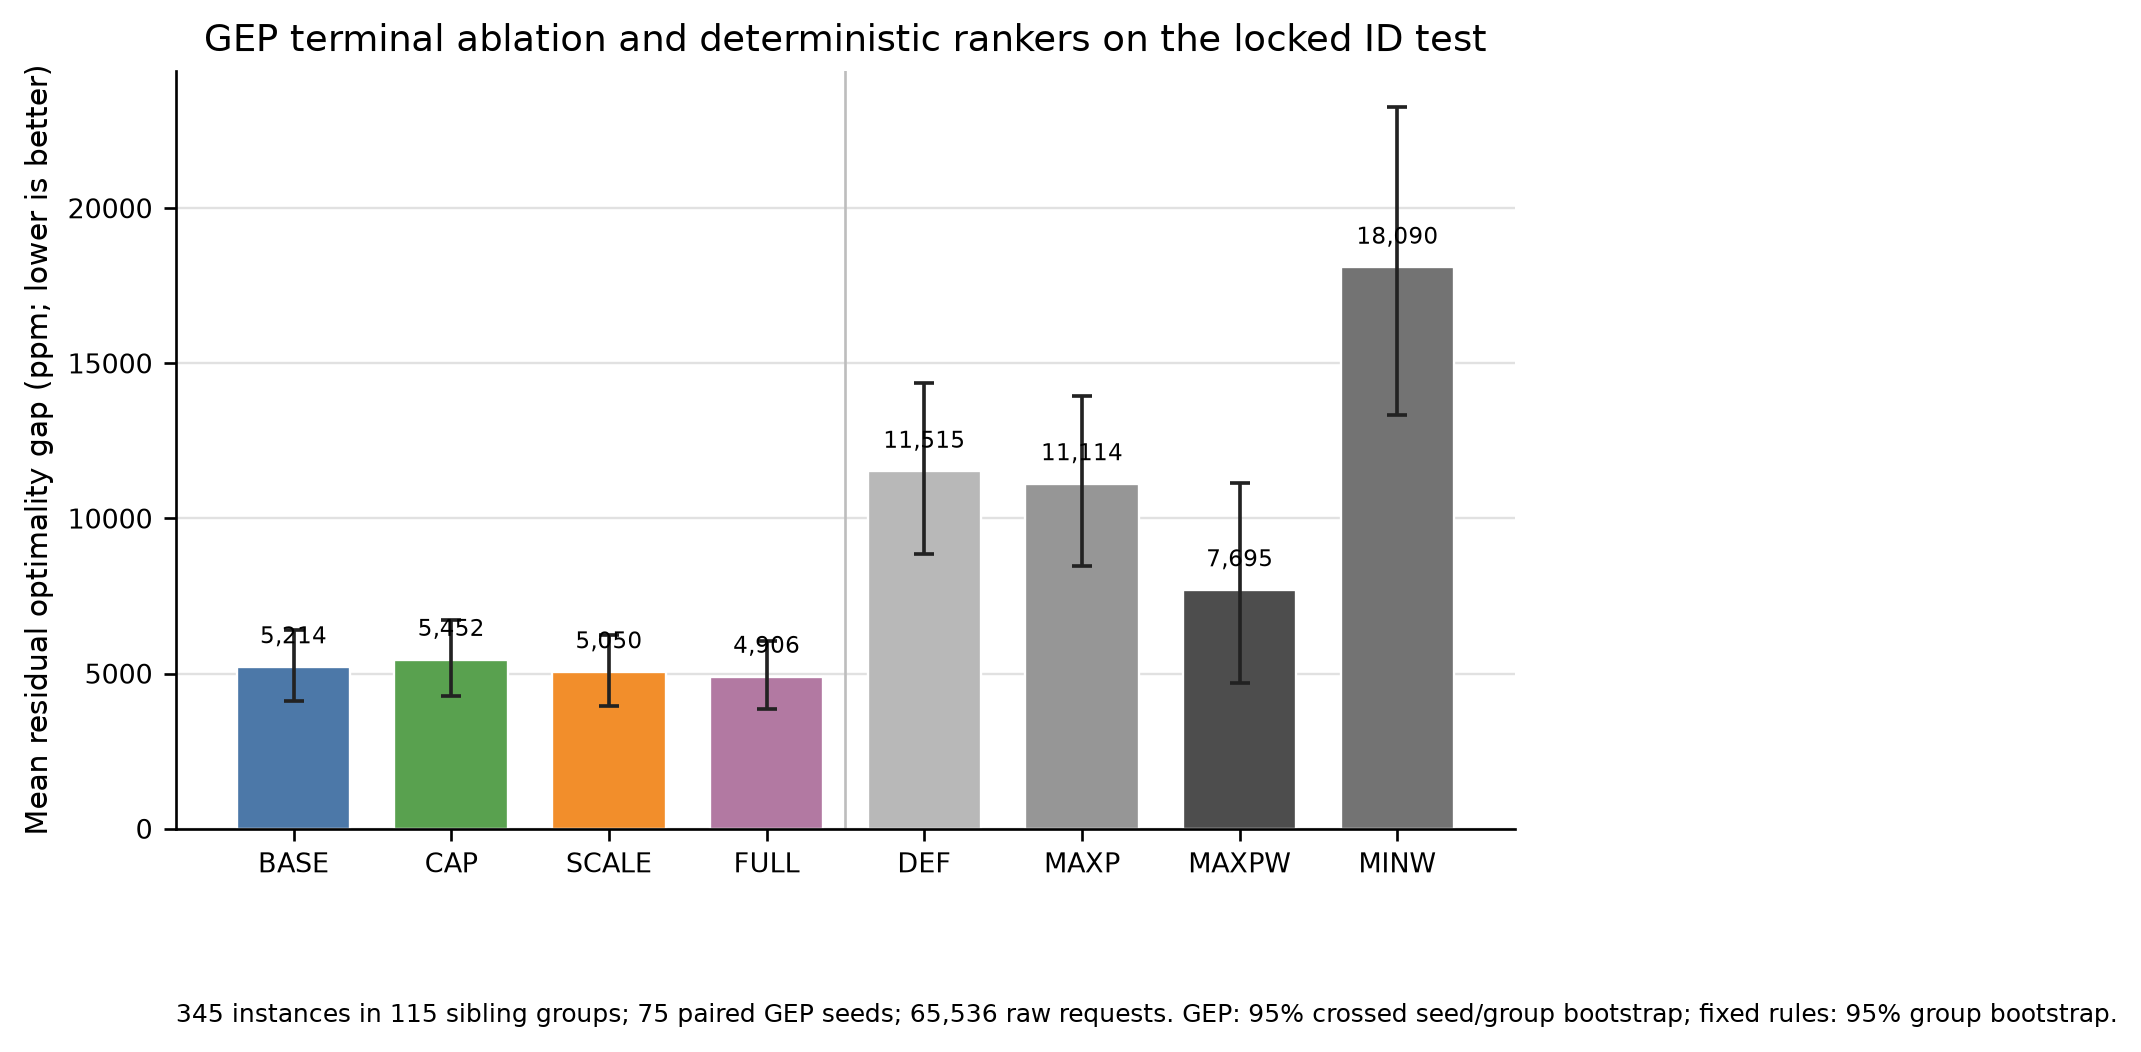

In [8]:
from src.analysis import HEADLINE_PATH, CONTRASTS_PATH, METHOD_SUMMARY_PATH
from src.config import FIGURES_ROOT

headline = pd.read_csv(HEADLINE_PATH)
display(headline)
display(Image(filename=str(FIGURES_ROOT / "headline_id_gap_v2.png")))

## Module 9 — What the planned tests actually say

The primary contrast is `FULL - BASE`; negative ppm favors `FULL`. The two
secondary contrasts are Holm-corrected. Equivalence is a separate question:
the 90% interval must fall completely inside $\pm872$ ppm.

,contrast,family,estimate_ppm,ci95_low_ppm,ci95_high_ppm,ci90_low_ppm,ci90_high_ppm,bootstrap_two_sided_p,paired_t_p,paired_wilcoxon_p,paired_dz,sesoi_ppm,tost_p,equivalent_at_872_ppm,holm_paired_t_p
0,FULL - BASE,primary,-308.167219,-640.372387,112.729557,-589.459920,28.401603,0.1216,0.028599,0.000813,-0.257801,872.0,5.526865e-05,True,0.028599
1,FULL - CAP,secondary,-546.365544,-1203.357363,-28.303760,-1089.738730,-107.097566,0.0388,0.001364,0.000269,-0.384301,872.0,2.550646e-02,False,0.002729
2,FULL - SCALE,secondary,-144.579885,-476.500590,279.047707,-429.230725,195.649500,0.4146,0.307732,0.021581,-0.118596,872.0,9.715633e-07,True,0.307732


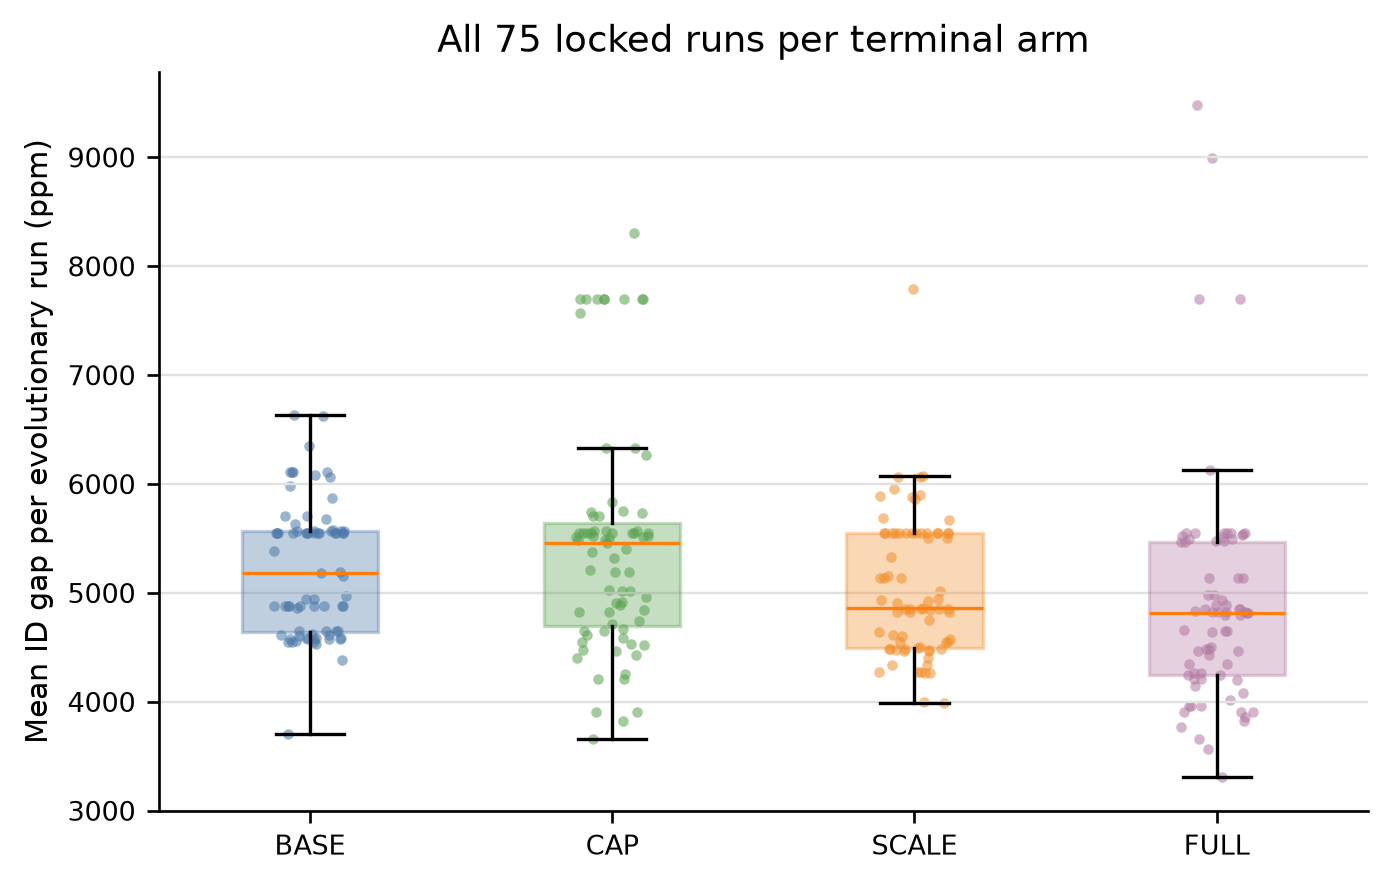

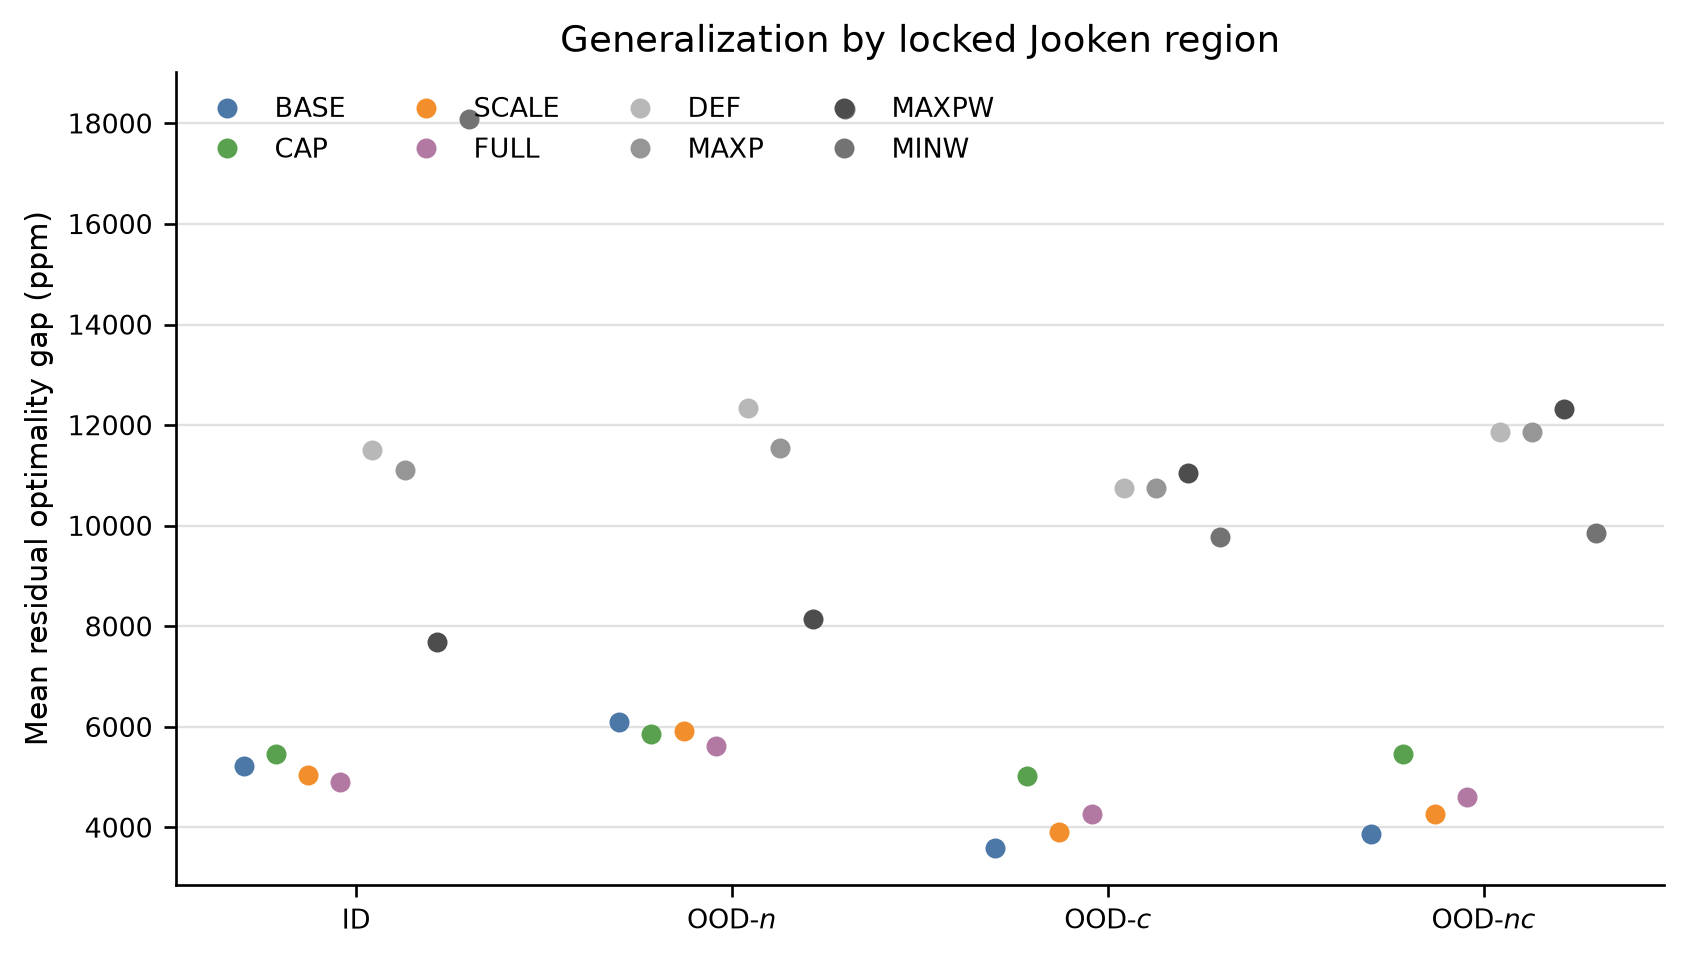

In [9]:
contrasts = pd.read_csv(CONTRASTS_PATH)
display(contrasts)
display(Image(filename=str(FIGURES_ROOT / "run_distribution_id_v2.png")))
display(Image(filename=str(FIGURES_ROOT / "generalization_regions_v2.png")))

## Module 10 — Budget, row order, and external transfer checks

The next figures answer three different questions: whether the search has
saturated, whether an expression exploits incidental item order, and whether a
Jooken-trained formula transfers without retuning to Pisinger's certified
classes.

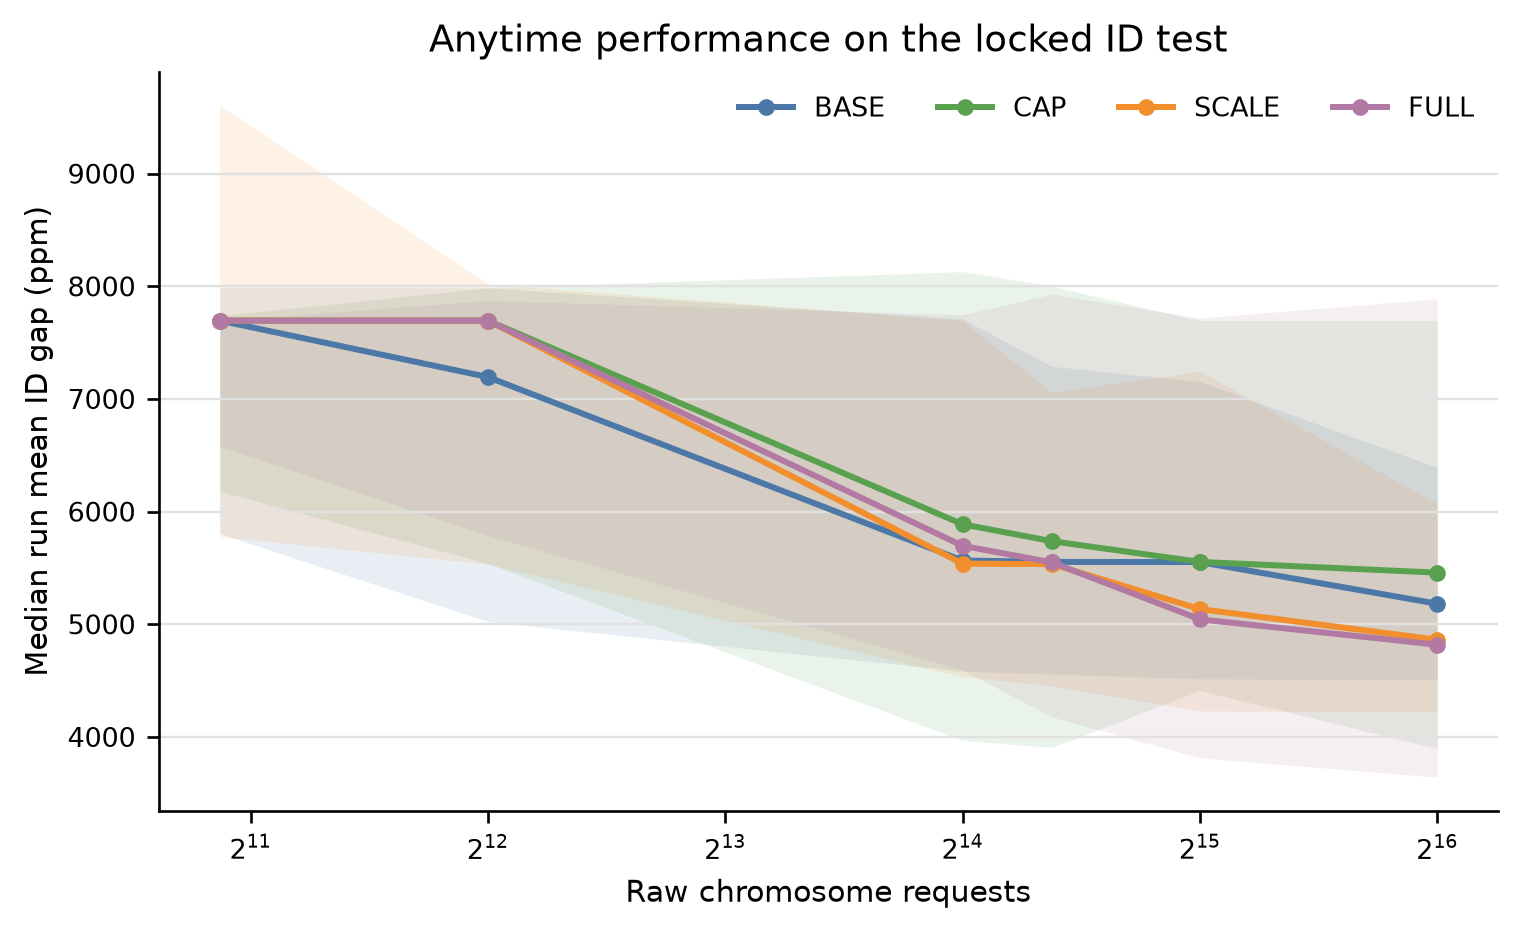

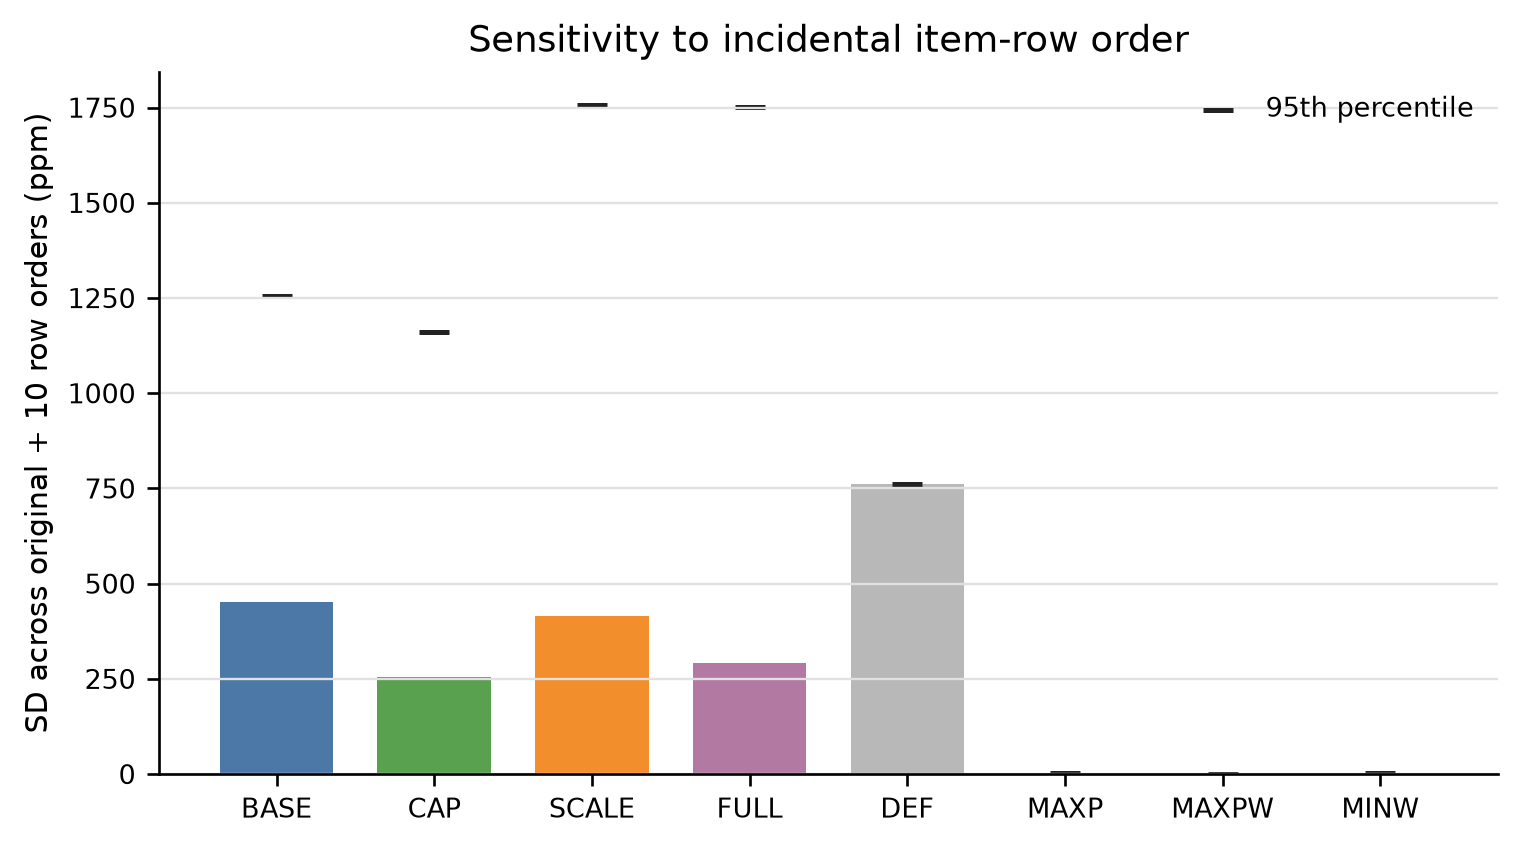

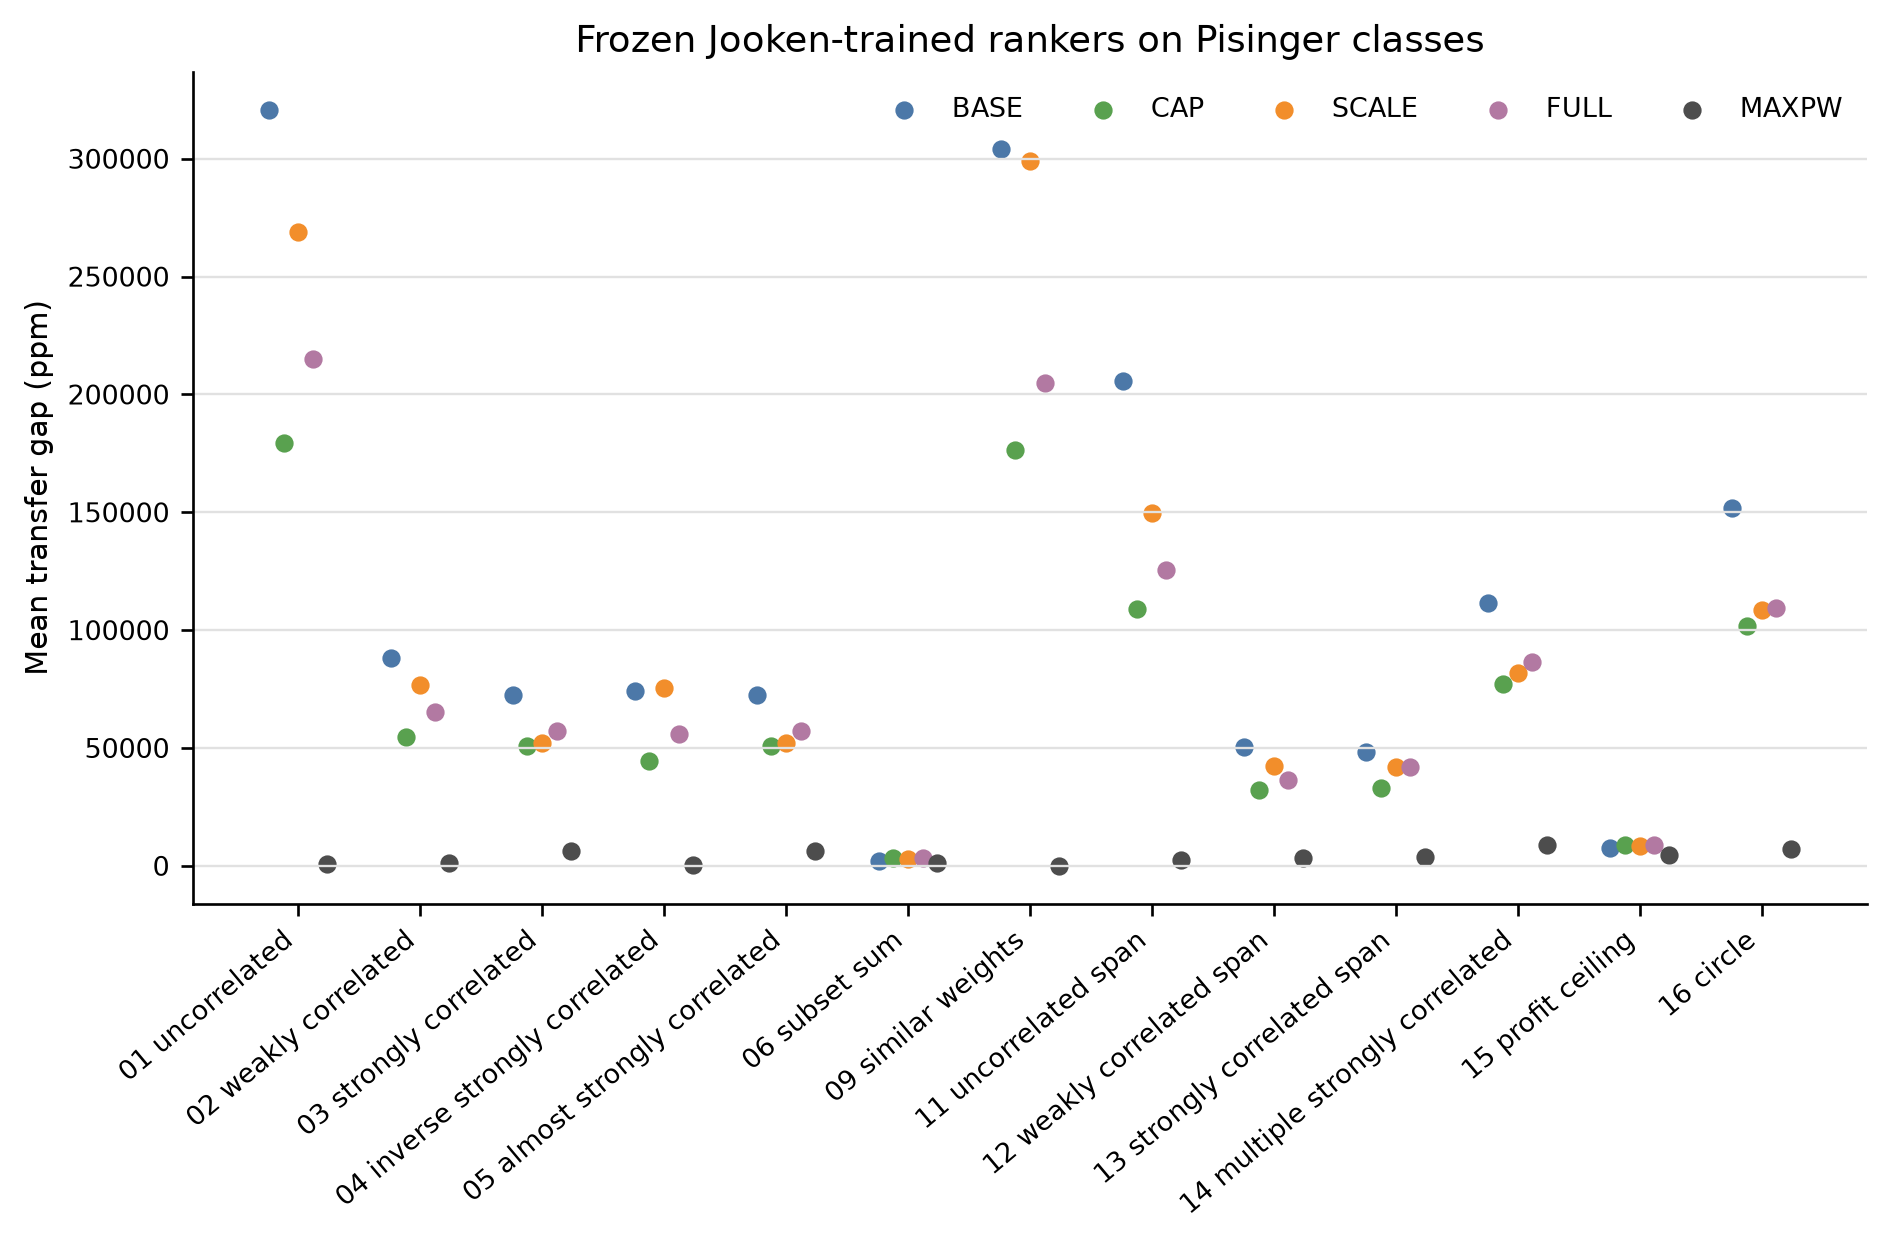

In [10]:
for filename in ("anytime_id_v2.png", "row_order_robustness_v2.png", "pisinger_transfer_v2.png"):
    path = FIGURES_ROOT / filename
    if path.is_file():
        display(Image(filename=str(path)))

## Module 11 — Recovered expressions

The representative is selected without looking at test outcomes: among models
within one development group-standard-error of the best development mean, take
the shortest ORF, then the lexicographically smallest simplified expression,
then the lowest run index. The full 75-expression list for every arm remains in
`results/expressions_v2.csv`.

In [11]:
representatives = pd.read_csv(RESULTS_ROOT / "representative_expressions_v2.csv")
ranking = pd.read_csv(RESULTS_ROOT / "ranking_equivalence_v2.csv")
representatives = representatives.merge(
    ranking[["model_id", "ranking_equivalent_to"]], on="model_id", how="left"
)
display(representatives[[
    "arm", "run", "simplified", "orf_length", "train_mean_gap_ppm",
    "eligibility_threshold_ppm", "eligible_models", "ranking_equivalent_to"
]])

all_expressions = pd.read_csv(RESULTS_ROOT / "expressions_v2.csv")
expression_counts = (
    all_expressions[all_expressions["family"] == "GEP"]
    .groupby(["arm", "simplified"])
    .size()
    .reset_index(name="runs")
    .sort_values(["arm", "runs", "simplified"], ascending=[True, False, True])
)
display(expression_counts.groupby("arm", group_keys=False).head(10))

,arm,run,simplified,orf_length,train_mean_gap_ppm,eligibility_threshold_ppm,eligible_models,ranking_equivalent_to
0,BASE,20,(P**2*(O + 2*W)*(P - 1) + W)/(P*(P - 1)),15,3618.621882,3862.015922,1,NaN
1,CAP,8,W + W/((K + P)*(P - 1)),11,3902.446405,4056.487641,9,NaN
2,SCALE,42,(-L*O*P + W)/(L*P*(2*W - 1)),13,3956.406867,4079.786437,11,NaN
3,FULL,71,(2*K - P)/(P*(L - 1)*(P + T)),17,2823.342823,3031.590188,1,NaN


,arm,simplified,runs
13,BASE,-1,21
16,BASE,-1/(P - 2*W**2),7
20,BASE,-W/(P*(P - 2*W**2)),7
17,BASE,-P**2 - P*W + P/W + W,3
38,BASE,W/(P**2*(2*W - 1)),3
0,BASE,(-O*W + P**3*(O - 2*W))/(O*P),1
1,BASE,(2*P*(2*W - 1) + W**2)/(2*W - 1),1
2,BASE,(3*P**2*(P - 1) + W)/(P*(P - 1)),1
3,BASE,(P + W)*(W*(1 - 2*W) + 1)/W,1
4,BASE,(P + W*(-P*(P + W) + W))/W,1


## Bottom line

Use the effect estimates and intervals in the contrast table, not a single best
run. A null result is still useful: it says the extra terminal information did
not reliably beat the accepted representation under a much stronger, paired,
externally checked protocol. A positive result is credible only if it survives
the same locked analysis.